# Дополнительный семинар 2. PMI/PPMI, LSA и многометочная классификация

На основном занятии мы превратили отзывы в TF-IDF и обучили классификатор тональности. Теперь разберём три вопроса, которые возникают при работе с текстами дальше.

### План семинара

1) Какие сочетания слов характерны для корпуса?

PMI/PPMI: сравним соседство с тем, что ожидали бы случайно

2) Можно ли описать документ меньшим числом координат?

LSA: объединим исходные признаки и проверим, что потерялось

3) Как предсказать сразу несколько меток текста?

Независимые LR и ClassifierChain: проверим пользу связей между ответами, на новых данных - будут комментарии GoEmotions

Душные моменты собраны в блоках **«Подробнее»**.

> Кстати, а в конце есть необязательное приложение о Feature hashing для обработки текстов без хранения словаря.

In [ ]:
%pip install -q "pandas==2.3.3" "scikit-learn==1.6.1" "matplotlib==3.9.4" "scipy>=1.13,<2"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 2.3.3 which is incompatible.


In [ ]:
import re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import coo_matrix, issparse
from IPython.display import display
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, HashingVectorizer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import f1_score

SEED = 13
LABELS = ["negative", "neutral", "positive"]
COLORS = ["#9b6b80", "#c5a46c", "#598c88"]
pd.set_option("display.max_colwidth", 180)
plt.rcParams.update({"figure.figsize": (9, 4), "font.size": 11})

## Подготовим данные

Снова берем [RuReviews](https://github.com/sismetanin/rureviews). Опять повторим подготовку основного семинара, чтобы дальше сравнивать методы на тех же отзывах.

Оставим нижний регистр, заменим ё на е, приведём пробелы к одному. Среди одинаковых формулировок отложим группы с разными метками, остальные повторы сведём к одной записи.


In [ ]:
url = "https://raw.githubusercontent.com/sismetanin/rureviews/2f6e61d30dc6c58ba47dce72e5803e1f0a3f38a7/women-clothing-accessories.3-class.balanced.csv"
raw = pd.read_csv(url, sep="\t").rename(columns={"review": "text_raw"})
raw.insert(0, "id", raw.index)
raw["label"] = raw["sentiment"].replace({"neautral": "neutral"})
raw.shape

(90000, 4)

In [ ]:
def normalize_text(text):
    return re.sub(r"\s+", " ", text.lower().replace("ё", "е")).strip()

nonempty = raw["text_raw"].fillna("").str.strip().ne("")
df = raw.loc[nonempty & raw["label"].isin(LABELS)].copy()
df["text"] = df["text_raw"].map(normalize_text)

In [ ]:
# возвращает для каждой строки число разных меток у той же формулировки
# gt(1) отмечает строки, у которых эта формулировка получила больше одной метки
conflict = df.groupby("text")["label"].transform("nunique").gt(1)

corpus = df.loc[~conflict].drop_duplicates("text").copy()

print("Отложили записей с разными метками одного текста:", int(conflict.sum()))
print("Осталось уникальных текстов:", len(corpus))

Отложили записей с разными метками одного текста: 2885
Осталось уникальных текстов: 85955


In [ ]:
sample, _ = train_test_split(
    corpus, train_size=30_000, stratify=corpus["label"], random_state=SEED
)
train, holdout = train_test_split(
    sample, test_size=0.30, stratify=sample["label"], random_state=SEED
)

valid, test = train_test_split(
    holdout, test_size=0.50, stratify=holdout["label"], random_state=SEED
)

split_counts = pd.DataFrame({
    "train": train["label"].value_counts(),
    "validation": valid["label"].value_counts(),
    "test": test["label"].value_counts(),
}).reindex(LABELS)
split_counts.loc["Всего"] = split_counts.sum()
split_counts

,train,validation,test
label,,,
negative,6976,1495,1495
neutral,6932,1485,1486
positive,7092,1520,1519
Всего,21000,4500,4500


## 1. Слова и их соседи: PMI и PPMI

Представим, что нужно разобраться в отзывах покупателей: какие выражения связаны с возвратом денег, доставкой и размером? Хотелось бы найти **характерные сочетания**, а затем посмотреть на похожие окружения слов.

Давайте посчитаем, какие слова стоят рядом. Поменяем логику: теперь строкой матрицы будет слово, а столбцом - слово из его окружения. Одна ячейка ответит, сколько раз встретилась такая пара.

Возьмём реальный отзыв. Для слова "платье" посмотрим по два токена слева и справа. Сначала токенизируем текст.

<details>
<summary>Про токенизацию в CountVectorizer</summary>

```
CountVectorizer(
    token_pattern=r"(?u)\b\w\w+\b", # минимум два символа
    lowercase=True, # приводить к нижнему регистру
    stop_words=None, # не удалять стоп-слова
)

а если хотим оставить пунктуацию: token_pattern=r"(?u)\b\w\w+\b|[^\w\s] или r"(?u)\b\w\w+\b|[^\w\s]+"
```

```
vectorizer = TfidfVectorizer(
    token_pattern=r"(?u)\b\w+\b", # сохраняем односимвольные слова
    ngram_range=(1, 2), # слова и пары соседних слов
    min_df=3, # минимум три документа
    sublinear_tf=True, # каждое дополнительное повторение слова увеличивает его вес всё меньше
)
```

</details>

In [ ]:
analyze = CountVectorizer().build_analyzer() # возвращает функцию с этой же токенизацией
window_example = train.set_index("id").loc[77284]

example_tokens = analyze(window_example["text"])
center = example_tokens.index("платье")

# по два токена с каждой стороны - не выходя за границы отзыва
positions = range(max(0, center - 2), min(len(example_tokens), center + 3))

print(window_example["text_raw"])

pd.DataFrame({
    "Позиция": list(positions),
    "Токен": [example_tokens[i] for i in positions],
    "Роль": ["Центральное слово" if i == center else "Контекст" for i in positions],
})

очень хорошее платье, точно в размер, очень красивое летнее платье:))


,Позиция,Токен,Роль
0,0,очень,Контекст
1,1,хорошее,Контекст
2,2,платье,Центральное слово
3,3,точно,Контекст
4,4,размер,Контекст


Каждый сосед добавит одно наблюдение в соответствующую ячейку. Повторим это для всех центральных слов во всех train-отзывах. Окно не выходит за границы отзыва. Пересечения между предложениями возможно.

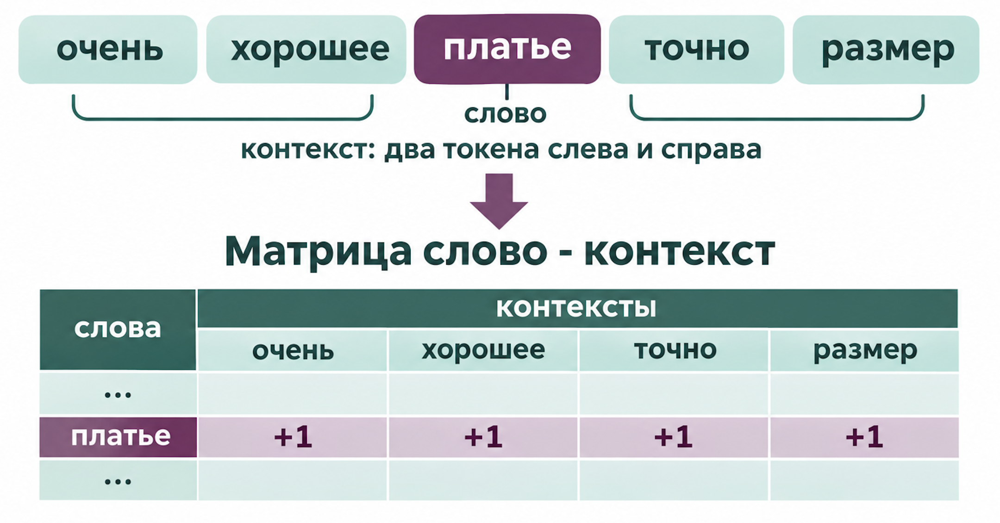

Чтобы матрица оставалась небольшой, возьмём 3 000 наиболее частых слов, встречающихся хотя бы в пяти отзывах.

In [ ]:
vocab_vectorizer = CountVectorizer(min_df=5, max_features=3000)

# только на train
vocab_vectorizer.fit(train['text'])
words = vocab_vectorizer.get_feature_names_out()
vocab = vocab_vectorizer.vocabulary_
analyze = vocab_vectorizer.build_analyzer()
tokenized = [analyze(text) for text in train['text']]

# vocab.get возвращает индекс или None
token_ids = [[vocab.get(token) for token in tokens] for tokens in tokenized]

In [ ]:
window = 2

# накапливаем число наблюдений для каждой пары индексов
pair_counts = Counter()
for ids in token_ids:
    for position, left in enumerate(ids):
        if left is None:
            continue

        # смотрим только вправо, но записываем пару в обоих направлениях
        for right in ids[position + 1:position + window + 1]:
            if right is not None:
                pair_counts[left, right] += 1
                pair_counts[right, left] += 1

rows = [pair[0] for pair in pair_counts]
cols = [pair[1] for pair in pair_counts]
counts = list(pair_counts.values())

# собираем матрицу из координат и частот - затем переходим к хранению по строкам
C = coo_matrix((counts, (rows, cols)), shape=(len(words), len(words))).tocsr()
print('Размер матрицы:', C.shape)

# nnz считает хранимые ненулевые ячейки
print('Ненулевых ячеек:', C.nnz)
# sum - все наблюдения с повторами
print('Всего пар с учётом направления:', C.sum())

Размер матрицы: (3000, 3000)
Ненулевых ячеек: 371083
Всего пар с учётом направления: 1185700


In [ ]:
pair_counts

Получилась матрица **слово - контекст**.

> Важная единица подсчёта - пара позиций: один отзыв может дать много наблюдений одной пары.

**Вопрос:** как изменилось бы окно, если бы перед подсчётом мы удалили все слова вне словаря?

### Частое соседство или характерное соседство?

Теперь хочется понять, какие пары выделяются. Тут нам помогут два метода. Поглядим на них.

- PMI - Pointwise Mutual Information, буквально "точечная взаимная информация".

PMI сравнивает, сколько раз мы увидели пару, - с тем, сколько ожидали бы при независимом выборе слова и контекста.

- PPMI - Positive Pointwise Mutual Information, положительная точечная взаимная информация

То есть метрика оставляет положительные значения PMI, а остальные просто заменяет нулём. Получается матрица связей, которые сильнее независимого ожидания.

<details>
<summary>Вероятности и формула PMI/PPMI</summary>

Пусть $C_{wc}$ - число наблюдений пары, $r_w=\sum_c C_{wc}$ - сумма строки, $s_c=\sum_w C_{wc}$ - сумма столбца, $S=\sum_{w,c}C_{wc}$ - общее число направленных пар. Все величины берём из одной матрицы $C$.

$$p(w,c)=\frac{C_{wc}}{S},\qquad p(w)=\frac{r_w}{S},\qquad p(c)=\frac{s_c}{S}.$$

При независимом выборе ожидали бы $E_{wc}=r_ws_c/S$ наблюдений. Поэтому:

$$\operatorname{PMI}(w,c)=\log_2\frac{p(w,c)}{p(w)p(c)}
=\log_2\frac{C_{wc}S}{r_ws_c}
=\log_2\frac{C_{wc}}{E_{wc}},\qquad
\operatorname{PPMI}(w,c)=\max(\operatorname{PMI}(w,c),0).$$

- $p(w,c)$ - наблюдаемая вероятность конкретной пары;
- $p(w)p(c)$ - вероятность этой пары, если выбор центрального слова и контекстного слова независим.

Для ненаблюдавшейся пары с положительными суммами строки и столбца PMI равен минус бесконечности в предельном смысле, а PPMI - нулю.


**Глянем на пример?**

Наша пара "платье - красивое". Допустим, после сбора контекстных окон получилось:

- всего **10 000 направленных пар**;
- в **1000 парах** центральное слово - "платье»"
- в **200 парах** контекстное слово - "красивое"

Если связи между ними нет, ожидаем совместных наблюдений:

$$
10\,000
\cdot \frac{1000}{10\,000}
\cdot \frac{200}{10\,000}
=20
$$

Но допустим, реально пара встретилась **80 раз**:

$$
\operatorname{PMI}(\text{платье},\text{красивое})
=
\log_2\frac{80}{20}
=
\log_2 4
=
2.
$$

**PMI = 2 означает, что пара встретилась в четыре раза чаще независимого ожидания.**

Можно посмотреть на те же числа иначе среди контекстов "платья" слово "красивое" встречается в $80/1000=8\%$ случаев, а среди всех контекстов - в $200/10000=2\%$. Знание центрального слова повышает вероятность этого контекста в четыре раза.

PPMI при ожидаемом числе наблюдений $20$ возможны такие ситуации:

| Реально наблюдали | Отношение к ожиданию | PMI | PPMI |
|---:|---:|---:|---:|
| 80 | В 4 раза чаще | 2 | 2 |
| 40 | В 2 раза чаще | 1 | 1 |
| 20 | Ровно столько, сколько ожидали | 0 | 0 |
| 10 | В 2 раза реже | -1 | 0 |
| 0 | Пара не наблюдалась | $-\infty$ | 0 |

> **PPMI сохраняет положительные ассоциации**, а информацию о том, насколько реже ожидания встречается пара, отбрасывает. Ноль в PPMI может означать и отсутствие наблюдений, и соседство на уровне независимого ожидания.
</details>

In [ ]:
# ravel превращает суммы по строкам и столбцам в одномерные массивы
row_total = np.asarray(C.sum(axis=1)).ravel()
col_total = np.asarray(C.sum(axis=0)).ravel()
total_pairs = C.sum()

# coo.data хранит частоты, coo.row и coo.col - индексы наблюдавшихся пар
coo = C.tocoo()

# считаем только наблюдавшиеся пары - ведь для остальных PPMI равен нулю
# по индексам coo.row и coo.col подставляем нужные суммы строк и столбцов
pmi_values = np.log2(
    coo.data.astype(float) * total_pairs /
    (row_total[coo.row] * col_total[coo.col])
)

PPMI = coo_matrix(
    (np.maximum(pmi_values, 0), (coo.row, coo.col)), shape=C.shape
).tocsr()

# удаляем явные нули
PPMI.eliminate_zeros()

In [ ]:
def pair_info(word, context):
    i, j = vocab[word], vocab[context]
    count = C[i, j]
    expected = row_total[i] * col_total[j] / total_pairs
    pmi = np.log2(count / expected) if count else -np.inf
    return {'Слово': word, 'Контекст': context, 'Наблюдений': count,
            'Ожидалось при независимости': expected,
            'PMI': pmi, 'PPMI': max(pmi, 0)}

pair_examples = pd.DataFrame([
    pair_info('деньги', 'вернули'), pair_info('размер', 'очень'),
    pair_info('желаю', 'удачи'), pair_info('маломерит', 'отстегивается'),
])
pair_examples.round({"Ожидалось при независимости": 6, "PMI": 3, "PPMI": 3})

,Слово,Контекст,Наблюдений,Ожидалось при независимости,PMI,PPMI
0,деньги,вернули,1170,36.338683,5.009,5.009
1,размер,очень,195,314.267474,-0.689,0.000
2,желаю,удачи,1,0.000863,10.179,10.179
3,маломерит,отстегивается,1,0.021071,5.569,5.569


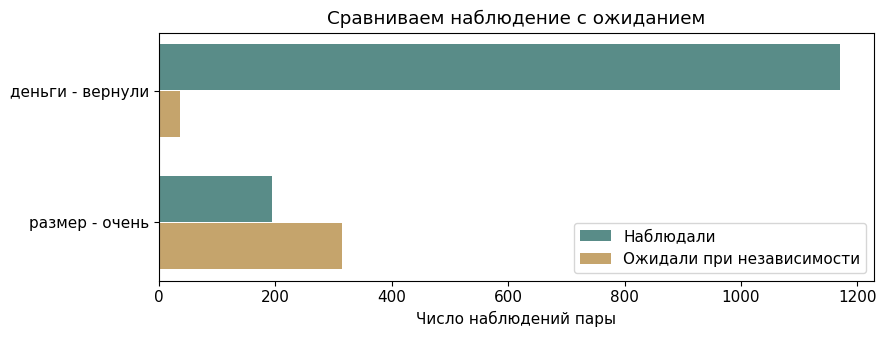

In [ ]:
pair_comparison = pair_examples.iloc[:2]
pair_labels = pair_comparison["Слово"] + " - " + pair_comparison["Контекст"]
pair_positions = np.arange(len(pair_comparison))
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.barh(pair_positions - 0.18, pair_comparison["Наблюдений"], height=0.35,
        label="Наблюдали", color=COLORS[2])
ax.barh(pair_positions + 0.18, pair_comparison["Ожидалось при независимости"], height=0.35,
        label="Ожидали при независимости", color=COLORS[1])
ax.set_yticks(pair_positions, pair_labels)
ax.invert_yaxis()
ax.set_xlabel("Число наблюдений пары")
ax.set_title("Сравниваем наблюдение с ожиданием")
ax.legend()
plt.tight_layout()
plt.show()

> При чтении таблицы держим рядом две величины: и силу связи, и число наблюдений, на которых она основана. Ведь высокий PMI по одному случаю может оказаться просто случайностью.

Теперь посмотрим на несколько слов сразу. На тепловой карте насыщенная ячейка означает высокую PPMI, а светлая - значение около нуля.


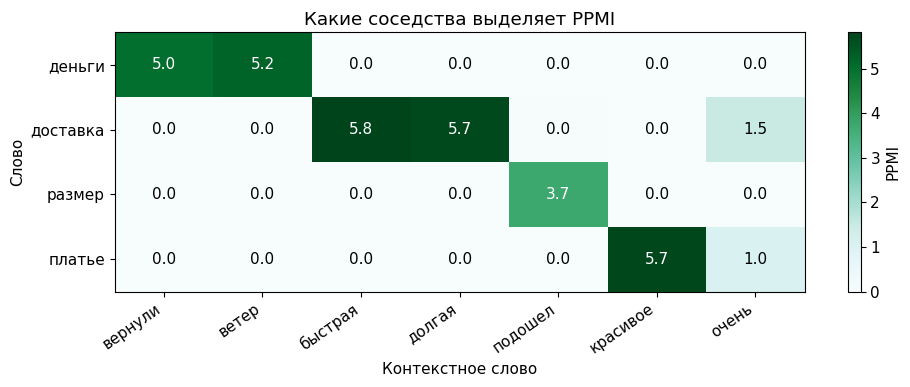

In [ ]:
plot_words = ["деньги", "доставка", "размер", "платье"]
plot_contexts = ["вернули", "ветер", "быстрая", "долгая", "подошел", "красивое", "очень"]
fragment = PPMI[[vocab[w] for w in plot_words]][:, [vocab[w] for w in plot_contexts]].toarray()
fig, ax = plt.subplots(figsize=(10, 4))
plot = ax.imshow(fragment, cmap="BuGn", vmin=0, aspect="auto")
ax.set_yticks(range(len(plot_words)), plot_words)
ax.set_xticks(range(len(plot_contexts)), plot_contexts, rotation=35, ha="right")
ax.set_xlabel("Контекстное слово")
ax.set_ylabel("Слово")
ax.set_title("Какие соседства выделяет PPMI")
for i in range(len(plot_words)):
    for j in range(len(plot_contexts)):
        value = fragment[i, j]
        ax.text(j, i, f"{value:.1f}", ha="center", va="center",
                color="white" if value > fragment.max() / 2 else "black")
fig.colorbar(plot, ax=ax, label="PPMI")
plt.tight_layout()
plt.show()

In [ ]:
def top_contexts(word, min_pairs=1, n=8):
    i = vocab[word]
    # выбираем строку слова со всеми его наблюдавшимися контекстами
    observed = C.getrow(i)

    # min_pairs фильтрует показ по частоте пары, не меняя саму матрицу PPMI
    columns = observed.indices[observed.data >= min_pairs]
    table = pd.DataFrame({
        'Контекст': words[columns],
        'Наблюдений пары': C[i, columns].toarray().ravel(),
        'PPMI': PPMI[i, columns].toarray().ravel(),
    })

    # сортируем по PPMI, затем по частоте
    return table.sort_values(['PPMI', 'Наблюдений пары'], ascending=False).head(n).reset_index(drop=True)

top_contexts('маломерит').round(3)

,Контекст,Наблюдений пары,PPMI
0,сильно,55,5.851
1,жутко,2,5.672
2,отстегивается,1,5.569
3,объеме,3,5.542
4,ххл,2,5.510
5,чашка,2,5.472
6,могут,1,5.381
7,нашу,1,5.215


**Задание 1. Проверим редкую связь**

Повторите вывод для "маломерит" с `min_pairs=10`. Какие соседи исчезли? Прочитайте отзыв 63246

In [ ]:
display(top_contexts('маломерит', min_pairs=10).round(3))
with pd.option_context('display.max_colwidth', None):
    display(train.loc[train['id'].eq(63246), ['id', 'text_raw']])

,Контекст,Наблюдений пары,PPMI
0,сильно,55,5.851
1,очень,62,2.261
2,заказала,14,2.173
3,размер,36,1.867
4,на,63,1.239
5,но,23,0.816
6,не,19,0.000


,id,text_raw
63246,63246,"блузка очень красивая, смотрится великолепно, брошь отстегивается, немного маломерит, на размер 44, ог 89 размер м маловат, поэтому блузку отдам сестре, а себе заказала размер L"


### Кто стоит рядом и кто похож по окружению

До сих пор мы смотрели на одну ячейку. Но всю строку PPMI можно использовать как **вектор слова**: каждая координата описывает его связь с одним контекстом. Если у двух слов похожи целые строки, они используются в похожем окружении.

| Что сравниваем | На какой вопрос отвечаем |
|---|---|
| Ячейку "размер - подошел" | Характерно ли для этих слов встречаться рядом? |
| Строки "размер" и "XL" | Похожи ли их связи со всеми контекстами? |

Сравним строки косинусным сходством.

<details>
<summary>Косинусное сходство строк PPMI</summary>

Для строк $a$ и $b$:

$$\cos(a,b)=\frac{a^\top b}{\|a\|_2\|b\|_2}.$$

После приведения ненулевых строк к единичной L2-норме их скалярное произведение равно косинусному сходству.

</details>

In [ ]:
# приводим ненулевые строки к единичной L2-норме
unit_ppmi = normalize(PPMI)

word = 'размер'

# сравниваем строку выбранного слова со всеми строками сразу
similarities = (unit_ppmi @ unit_ppmi[vocab[word]].T).toarray().ravel()

similarities[vocab[word]] = -1 # не показываем само слово

# минус перед сходством дает сортировку от большего к меньшему
nearest = np.argsort(-similarities)[:8]

display(top_contexts(word, min_pairs=10).round(3))
display(pd.DataFrame({'Слово': words[nearest], 'Cosine': similarities[nearest]}).round(3))

,Контекст,Наблюдений пары,PPMI
0,единый,13,4.313
1,подошел,478,3.734
2,маленький,138,3.303
3,правильный,11,3.291
4,поменьше,11,3.203
5,выбрала,21,3.197
6,выбирала,18,3.146
7,указан,29,3.045


,Слово,Cosine
0,xl,0.438
1,48,0.438
2,46,0.432
3,44,0.402
4,42,0.398
5,российский,0.395
6,русский,0.394
7,взяла,0.387


У слова "размер" среди сильных отдельных связей есть "подошел", а среди похожих строк - "XL" и числовые размеры.

По итогу - мы получили способ исследовать характерные выражения и находить слова с похожими контекстами.

> Выбор токенизации, окна и словаря влияет на результат, а редкие связи требуют проверки по исходным текстам.

Теперь вернемся к **документам**. В следующем опыте исходной матрицей снова будет TF-IDF отзывов и мы  попробуем заменить тысячи её столбцов небольшим числом новых координат.

## 2. LSA - Latent Semantic Analysis

В TF-IDF каждому слову соответствует отдельный столбец. При этом некоторые слова регулярно встречаются в одних и тех же документах: в одних отзывах обсуждают возврат денег и спор с продавцом, в других - размер и качество вещи. Можно ли использовать такие закономерности и описать отзыв меньшим числом координат?

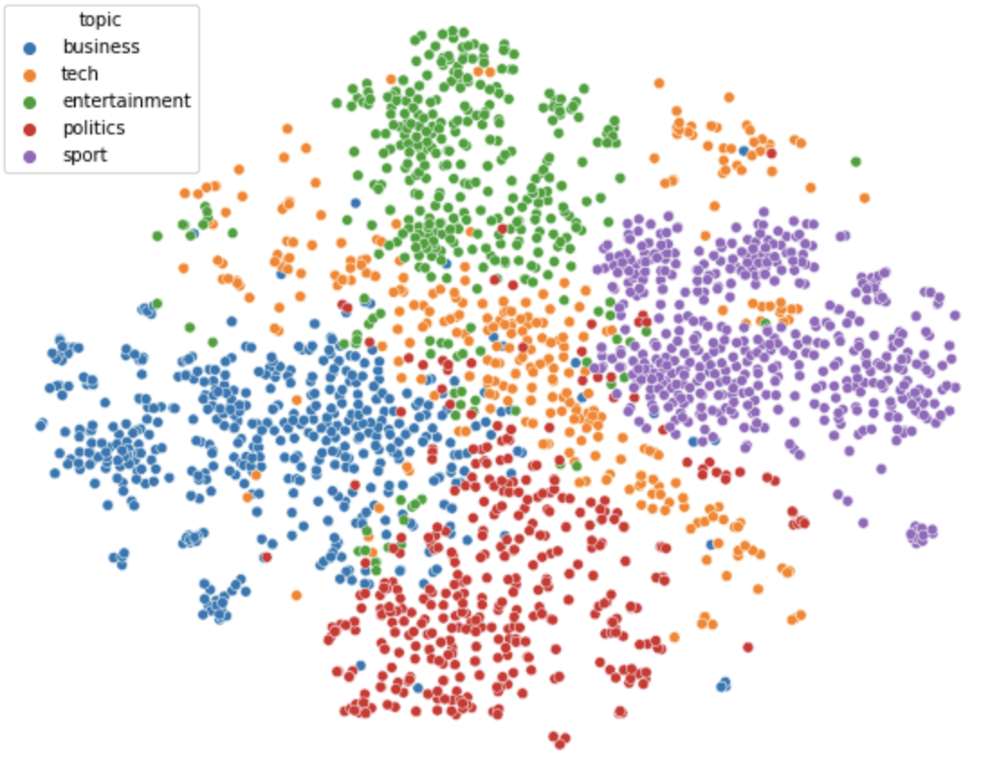

**LSA строит новые координаты как взвешенные суммы исходных текстовых признаков.** Одна координата собирает информацию сразу о нескольких словах. Число отзывов сохраняется, число признаков уменьшается. Такие векторы удобно передавать дальше в классификатор или использовать для поиска похожих документов.

Веса новых координат находим с помощью `TruncatedSVD`. Разложение подбирает направления, через которые можно приближённо описать исходную матрицу.

Проверим 100 и 200 координат. Сравним качество с исходным TF-IDF, расходы памяти, а затем прочитаем ближайшие отзывы. Так станет видно, что именно нам дало преобразование.

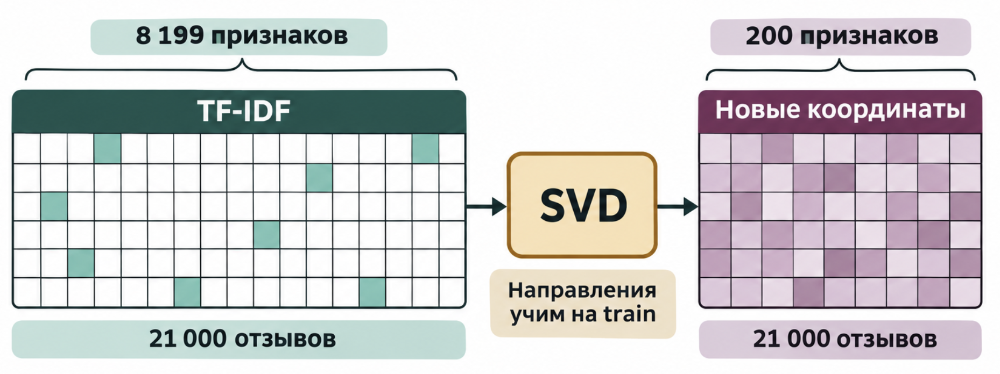

<details>
<summary>Подробнее: SVD, размеры матриц и проекция нового текста</summary>

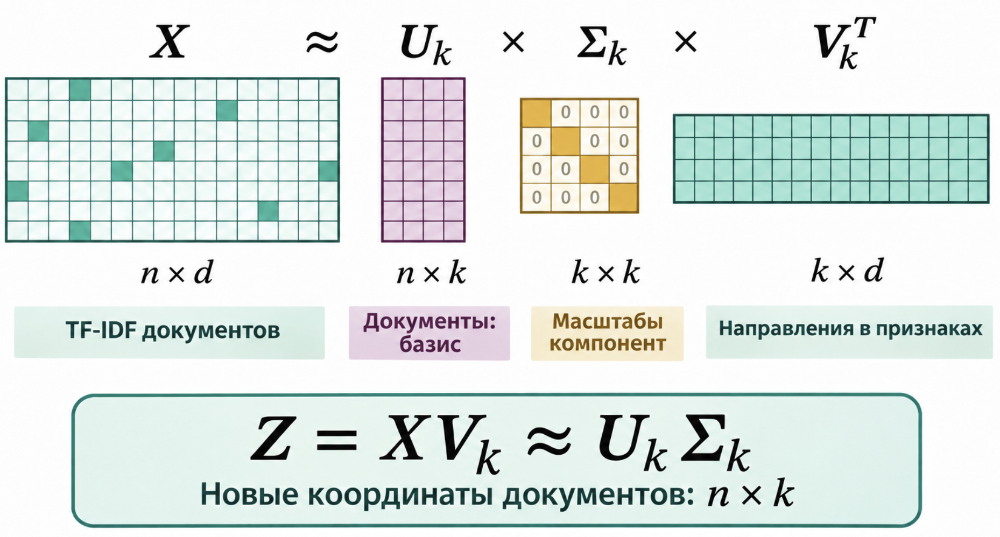

На рисунке условные сетки: они показывают совместимые размеры матриц. В нашем опыте n = 21 000, d = 8 199, k = 100 или 200.

Пусть $X$ имеет размер $n\times d$: $n$ документов и $d$ исходных признаков. Усечённое сингулярное разложение оставляет $k$ компонент:

$$X\approx U_k\Sigma_kV_k^\top.$$

$U_k$ имеет размер $n\times k$, диагональная матрица $\Sigma_k$ - $k\times k$, а $V_k$ - $d\times k$. Столбцы $V_k$ задают новые направления в исходных признаках. Столбцы $U_k$ описывают соответствующие направления со стороны документов и нормированы. На диагонали $\Sigma_k$ стоят неотрицательные сингулярные числа: масштабы компонент, упорядоченные от больших к меньшим. Чтобы получить координаты документов с этими масштабами, нужно учесть и $U_k$, и $\Sigma_k$. Через исходную матрицу их получаем проекцией:

$$Z=XV_k\approx U_k\Sigma_k,\qquad z_{ij}=\sum_{t=1}^{d}X_{it}(V_k)_{tj}.$$

В этом опыте $d=8199$, а $k$ равен 100 или 200. Для новых текстов используем уже обученный TF-IDF и ту же матрицу направлений: $Z_{new}=X_{new}V_k$.

SVD - общий метод разложения матрицы; LSA - его применение к текстовому представлению. В отличие от PCA, `TruncatedSVD` не вычитает среднее по столбцам, поэтому работает непосредственно с разреженной матрицей. Разложение ищет хорошее приближение матрицы, а не максимальный F1 классификатора.

</details>

In [ ]:
tfidf_vec = TfidfVectorizer(ngram_range=(1, 1), min_df=3, max_df=0.95, max_features=50_000)
X_train = tfidf_vec.fit_transform(train["text"])
X_valid = tfidf_vec.transform(valid["text"])

tfidf_clf = LogisticRegression(C=1.0, max_iter=500, random_state=SEED)
tfidf_clf.fit(X_train, train["label"])
tfidf_pred = tfidf_clf.predict(X_valid)

print("Размер TF-IDF:", X_train.shape)
print("Macro-F1 на validation:", round(f1_score(valid["label"], tfidf_pred, average="macro"), 3))

Размер TF-IDF: (21000, 8199)
Macro-F1 на validation: 0.723


Исходный TF-IDF дал 8 199 признаков. Теперь заменим их новыми координатами и обучим такую же логистическую регрессию. После проекции приведём ненулевые строки к единичной длине: сравниваем вариант **TF-IDF -> SVD -> L2 -> классификатор** с исходным TF-IDF.

Направления SVD учим только на train. Validation проходит через уже найденные направления, как новый отзыв на схеме.

<details>
<summary>Подробнее: L2-нормировка после проекции</summary>

После проекции каждый ненулевой вектор $z$ делим на его длину:

$$\widetilde z=\frac{z}{\sqrt{\sum_j z_j^2}}.$$

Так на входе LR сравниваются нормированные представления. Нормировка не возвращает информацию, отброшенную при снижении размерности.

</details>

In [ ]:
lsa_results = [{
    "Представление": "TF-IDF",
    "Признаков": X_train.shape[1],
    "Macro-F1 на validation": f1_score(valid["label"], tfidf_pred, average="macro"),
}]
lsa_models = {}
for k in [100, 200]:
    # n_components - число координат, n_iter - уточнения приближённого разложения
    # по умолчанию используется randomized; random_state фиксирует случайность
    svd = TruncatedSVD(n_components=k, n_iter=5, random_state=SEED)

    # fit_transform находит направления на train и проецирует его, normalize делает L2-нормировку
    Z_train = normalize(svd.fit_transform(X_train))

    # transform применяет к validation уже найденные направления
    Z_valid = normalize(svd.transform(X_valid))
    clf = LogisticRegression(C=1.0, max_iter=500, random_state=SEED)
    clf.fit(Z_train, train["label"])
    prediction = clf.predict(Z_valid)
    lsa_models[k] = {"svd": svd, "clf": clf, "train": Z_train, "valid": Z_valid}
    lsa_results.append({
        "Представление": f"LSA {k} + L2",
        "Признаков": k,
        "Macro-F1 на validation": f1_score(valid["label"], prediction, average="macro"),
    })
lsa_results = pd.DataFrame(lsa_results).set_index("Представление")
lsa_results.round(3)

,Признаков,Macro-F1 на validation
Представление,,
TF-IDF,8199,0.723
LSA 100 + L2,100,0.697
LSA 200 + L2,200,0.711


Координат стало меньше, но качество в этом опыте снизилось. SVD сохраняет крупные закономерности матрицы, а для тональности может быть важно и небольшое различие, например отрицание рядом с оценочным словом.

Посмотрим, какую долю дисперсии объясняют выбранные направления. График показывает, насколько различаются документы вдоль сохранённых осей. Это не доля сохранённого «смысла» и не доля правильных ответов модели.

<details>
<summary>Подробнее: доля объяснённой дисперсии</summary>

Для выхода SVD **до последующей L2-нормировки** доля компоненты $j$ рассчитывается как отношение дисперсии её координат к суммарной дисперсии исходных признаков:

$$q_j=\frac{\operatorname{Var}(Z_{:j})}{\sum_{t=1}^{d}\operatorname{Var}(X_{:t})}.$$

Кривая построена по первым компонентам одного разложения на 200 компонент. Отдельный запуск на 100 компонент приближённый, поэтому его сумма может немного отличаться от точки 100 на кривой.

Для нецентрированного SVD эту величину не следует автоматически заменять долей суммы квадратов сингулярных чисел. Метки классов в расчёте не участвуют; большая объяснённая дисперсия не гарантирует высокий F1.

</details>

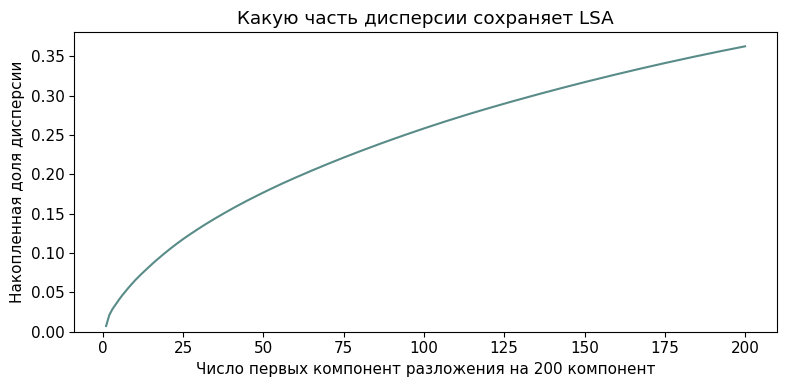

,Доля объяснённой дисперсии
LSA 100,0.257
LSA 200,0.363


In [ ]:
svd_200 = lsa_models[200]["svd"]
fig, ax = plt.subplots(figsize=(8, 4))

# explained_variance_ratio_ содержит доли компонент до L2, а cumsum накапливает их
ax.plot(np.arange(1, 201), np.cumsum(svd_200.explained_variance_ratio_), color=COLORS[2])
ax.set_xlabel("Число первых компонент разложения на 200 компонент")
ax.set_ylabel("Накопленная доля дисперсии")
ax.set_title("Какую часть дисперсии сохраняет LSA")
ax.set_ylim(bottom=0)
plt.tight_layout()
plt.show()

pd.Series({
    f"LSA {k}": result["svd"].explained_variance_ratio_.sum()
    for k, result in lsa_models.items()
}, name="Доля объяснённой дисперсии").round(3)

### Меньше координат это меньше памяти?

Для практической работы важно понять и цену нового представления. TF-IDF содержит много нулей: разреженный формат хранит ненулевые значения и их адреса. После SVD матрица плотная: память выделена под все координаты каждого отзыва.

Поэтому меньшее число столбцов ещё не означает меньший объём. Сравним сами матрицы train и отдельно направления SVD. Это объём числовых массивов, а не пиковая память всей программы.

<details>
<summary>Подробнее: как считаем объём матриц</summary>

В CSR память расходуется на ненулевые значения, номера их столбцов и указатели начала строк. В плотной матрице хранятся все элементы. В таблице MB - миллион байт.

Для $n=21000$, $k=200$ и 8 байт на число плотная матрица занимает $21000\cdot200\cdot8=33\,600\,000$ байт. Дополнительно нужно хранить $k\times d$ весов направлений, чтобы преобразовывать новые отзывы. Память словаря, классификатора и временных массивов здесь не измеряем.

</details>

In [ ]:
def matrix_mb(matrix):
    # issparse проверяет формат: у CSR учитываем значения, индексы столбцов и указатели строк
    if issparse(matrix):
        return (matrix.data.nbytes + matrix.indices.nbytes + matrix.indptr.nbytes) / 1_000_000
    # у плотного массива nbytes включает все элементы; переводим байты в MB
    return matrix.nbytes / 1_000_000

memory_rows = [{
    "Представление": "TF-IDF (CSR)",
    "Столбцов": X_train.shape[1],
    "Матрица train, MB": matrix_mb(X_train),
    "Направления SVD, MB": 0,
}]
for k, result in lsa_models.items():
    memory_rows.append({
        "Представление": f"LSA {k} (плотная)",
        "Столбцов": k,
        "Матрица train, MB": matrix_mb(result["train"]),
        "Направления SVD, MB": matrix_mb(result["svd"].components_),
    })
memory_table = pd.DataFrame(memory_rows).set_index("Представление")
memory_table.round(2)

,Столбцов,"Матрица train, MB","Направления SVD, MB"
Представление,,,
TF-IDF (CSR),8199,4.37,0.00
LSA 100 (плотная),100,16.80,6.56
LSA 200 (плотная),200,33.60,13.12


В нашем корпусе плотные векторы заняли больше памяти, хотя координат стало меньше. При выборе размерности нужно смотреть на формат хранения и на последующие операции, а не только на число столбцов.

**Задание 3. Выберем размерность**

Сопоставьте качество, размерность и память для 100 и 200 компонент. Есть ли здесь основание заменить исходный TF-IDF на LSA именно для классификации тональности?

Дополнительно: проверьте 50 компонент, сохранив остальные настройки.

### Что означают новые координаты?

Мы уже знаем, что новая координата складывается из исходных признаков с весами. Теперь прочитаем сами веса. Какие слова вносят самый большой положительный и отрицательный вклад в одну из осей?

Удобная интерпретация может подсказать, какую закономерность нашло разложение. Но компонента не обязана быть отдельной понятной темой или распределением вероятностей по словам.

<details>
<summary>Подробнее: почему знак направления неоднозначен</summary>

Если поменять знак столбца $V_k$ и соответствующего столбца $U_k$, произведение $U_k\Sigma_kV_k^\top$ не изменится. Координаты документов по этой оси тоже сменят знак. Поэтому «положительный» и «отрицательный» здесь не означают хорошую или плохую тональность; важно само противопоставление слов.

</details>

In [ ]:
# индексы начинаются с нуля: берём второе направление
component = 1

# components_ хранит транспонированную V размером k × d, строка - веса одного направления
weights = svd_200.components_[component]

# слова идут в том же порядке, что и столбцы TF-IDF
terms = tfidf_vec.get_feature_names_out()

# сортировка весов позволяет выбрать оба конца оси
order = np.argsort(weights)
pd.DataFrame({
    "Большие положительные веса": terms[order[-8:][::-1]],
    "Большие отрицательные веса": terms[order[:8]],
})

,Большие положительные веса,Большие отрицательные веса
0,деньги,на
1,вернули,очень
2,пришел,размер
3,товар,качество
4,не,доставка
5,спор,как
6,продавец,хорошее
7,заказ,все


На одном конце этой оси оказались «деньги», «вернули», «спор», на другом - слова о размере и качестве. Это помогает прочитать направление, но не делает его готовой меткой темы.

Посмотрим на другое применение: поиск похожих отзывов. Возьмём знакомый текст из validation и найдём три ближайших отзыва из train. Сравним соседей в TF-IDF и после LSA. В обоих случаях используем косинусное сходство; строки уже нормированы, поэтому достаточно скалярного произведения.

In [ ]:
example_id = 80096
example_position = valid.index.get_loc(example_id)
print(valid.loc[example_id, "text_raw"])

def nearest_reviews(scores, n=3):
    indices = np.argsort(-scores, kind="stable")[:n]
    result = train.iloc[indices][["id", "text_raw"]].copy()
    result["Cosine"] = scores[indices]
    return result.set_index("id").round({"Cosine": 3})

sparse_scores = (X_train @ X_valid[example_position].T).toarray().ravel()
latent_scores = lsa_models[200]["train"] @ lsa_models[200]["valid"][example_position]
with pd.option_context("display.max_colwidth", None):
    print("Соседи в TF-IDF")
    display(nearest_reviews(sparse_scores))
    print("Соседи в LSA, 200 компонент")
    display(nearest_reviews(latent_scores))

доставка 3 недели. платье не плохое.  своих денег стоит.
Соседи в TF-IDF


,text_raw,Cosine
id,,
24878,Не стоит своих денег!,0.728
31565,качество не понравилось.не стоит своих денег,0.613
14219,"платье из простыни, просвечивает. своих денег не стоит. полное г....",0.569


Соседи в LSA, 200 компонент


,text_raw,Cosine
id,,
73052,"прекрасное качественное платье, своих денег стоит)",0.784
1750,"качество плохое все отклеивается, не стоит этих денег",0.758
24878,Не стоит своих денег!,0.718


После LSA первым соседом стал положительный отзыв «своих денег стоит». Но среди ближайших остались и противоположные оценки покупки. Значит, преобразование изменило близость документов, а надёжно учитывать отрицания мы этим ещё не научились.

Для текущего классификатора тональности исходный TF-IDF оказался полезнее: он дал лучший F1 и меньший объём матрицы train. LSA имеет смысл проверять, когда нужны векторы небольшой размерности или другое представление сходства, но эти преимущества оценивают вместе с потерями.

**Вопрос:** какие слова сблизили эти отзывы? Какую информацию о тональности хотелось бы сохранить лучше?

- До сих пор мы меняли признаки, сохраняя одну метку тональности у отзыва. Теперь рассмотрим ситуацию, в которой сам ответ устроен иначе: у текста может быть несколько меток.

## ClassifierChain: несколько меток у одного текста

У обращения в поддержку может быть сразу несколько тем: покупатель одновременно жалуется на доставку и просит вернуть деньги. Аналитику важно найти его в обеих категориях. Если заставить модель выбрать единственную тему, часть информации потеряется.

В RuReviews каждый отзыв имел одну метку из трёх - это **многоклассовая классификация (multiclass)**. Когда одному объекту можно назначить несколько меток одновременно, задача называется **многометочной классификацией (multilabel)**.

LSA менял признаки текста. Здесь изменится способ предсказывать ответы: сравним отдельную модель для каждой метки с цепочкой, в которой модели используют предыдущие предсказания. Для этого эксперимента снова возьмём обычный TF-IDF.

### Комментарии с несколькими эмоциями

Возьмём [GoEmotions](https://github.com/google-research/google-research/tree/master/goemotions): короткие англоязычные комментарии Reddit с ручной разметкой. В этой версии у комментария оставлены метки, с которыми согласились как минимум два разметчика. Всего 27 эмоций и `neutral`, мы будем использовать всё.

Данные уже разделены авторами на train, dev и test. Загрузим train и dev, который будем называть validation. Столбец `labels` содержит номера эмоций через запятую (их названия лежат в отдельном файле).

In [ ]:
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.multioutput import ClassifierChain
from sklearn.metrics import accuracy_score

emotion_url = (
    "https://raw.githubusercontent.com/google-research/google-research/"
    "2adf640a14f11025ae5a9d0ec493b78530d276d3/goemotions/data/"
)

# в TSV кавычки входят в текст: quoting=3 сохраняет их при чтении
emotion_read_options = dict(
    sep="\t", names=["text", "labels", "id"], dtype=str,
    keep_default_na=False, quoting=3,
)
emotion_train_raw = pd.read_csv(emotion_url + "train.tsv", **emotion_read_options)
emotion_valid_raw = pd.read_csv(emotion_url + "dev.tsv", **emotion_read_options)
emotion_names = pd.read_csv(emotion_url + "emotions.txt", header=None)[0].tolist()

pd.Series({"train": len(emotion_train_raw), "validation": len(emotion_valid_raw),
           "меток": len(emotion_names)})

,0
train,43410
validation,5426
меток,28


В данных встречаются дословные повторы. Для этого опыта исключим все строки с повторяющимся текстом внутри каждой части, а из validation также уберём тексты, встречавшиеся в исходном train.

In [ ]:
emotion_train = emotion_train_raw.drop_duplicates("text", keep=False).copy()
emotion_valid = emotion_valid_raw.drop_duplicates("text", keep=False).copy()
emotion_valid = emotion_valid.loc[
    ~emotion_valid["text"].isin(emotion_train_raw["text"])
].copy()

def emotion_ids(value):

    # превращаем строку "0,15" в список числовых индексов
    return [int(label) for label in value.split(",")]

# фиксируем все 28 столбцов, binarizer превращает списки меток в плотную матрицу 0/1
emotion_binarizer = MultiLabelBinarizer(classes=range(len(emotion_names)))

Y_emotion_train = emotion_binarizer.fit_transform(emotion_train["labels"].map(emotion_ids))

# для validation сохраняем тот же порядок столбцов
Y_emotion_valid = emotion_binarizer.transform(emotion_valid["labels"].map(emotion_ids))

print("Train:", Y_emotion_train.shape)
print("Validation:", Y_emotion_valid.shape)
print(f"Несколько меток в train: {(Y_emotion_train.sum(axis=1) > 1).mean():.1%}")

Train: (43109, 28)
Validation: (5381, 28)
Несколько меток в train: 16.4%


Теперь строка $Y$ соответствует комментарию, а столбец - метке. Единица означает, что метка есть в разметке, ноль - что её нет. В одной строке может быть несколько единиц.

Посмотрим на четыре комментария из train. Для компактности покажем только три столбца: `admiration` - восхищение, `gratitude` - благодарность, `joy` - радость. Модели будут предсказывать все 28.

<details>
<summary>Подробнее: размеры X и Y</summary>

$X$ имеет размер $n\times d$, а $Y$ - $n\times L$, где $L=28$. $Y_{ij}=1$, если у комментария $i$ есть метка $j$. Сумма строки $Y$ показывает количество меток комментария.

</details>

In [ ]:
emotion_example_ids = ["eeqd04y", "efeu6uo", "eeezvpp", "eejax15"]
emotion_example_rows = emotion_train.set_index("id").loc[emotion_example_ids]
emotion_example_y = emotion_binarizer.transform(
    emotion_example_rows["labels"].map(emotion_ids)
)
emotion_example_table = pd.DataFrame(
    emotion_example_y, index=emotion_example_ids, columns=emotion_names
)
emotion_example_table.insert(0, "text", emotion_example_rows["text"])
emotion_example_table[["text", "admiration", "gratitude", "joy"]]

,text,admiration,gratitude,joy
eeqd04y,Thank you friend,0,1,0
efeu6uo,Happy to be able to help.,0,0,1
eeezvpp,Awesome. Thanks!,1,1,0
eejax15,Thanks! We had fun.,0,1,1


### Сначала попробуем независимые модели

Самое простое решение - обучить по одной бинарной логистической регрессии на каждую метку. Одна отвечает на вопрос «есть ли благодарность?», другая - «есть ли радость?», и так далее. Каждая получает один и тот же TF-IDF текста.

Сумма вероятностей этих моделей не обязана равняться единице: метки не исключают друг друга. При стандартном пороге 0.5 можно получить одну, несколько или ни одной метки.

Но некоторые эмоции встречаются вместе. Посмотрим, какие пары чаще всего есть в разметке train.

<details>
<summary>Подробнее: совместная встречаемость меток</summary>

В матрице $Y^\top Y$ ячейка $(j,k)$ равна $\sum_iY_{ij}Y_{ik}$: числу комментариев, у которых одновременно есть обе метки. На диагонали стоит число примеров каждой отдельной метки.

</details>

In [ ]:
emotion_joint = pd.DataFrame(
    Y_emotion_train.T @ Y_emotion_train,
    index=emotion_names, columns=emotion_names,
)
# triu с k=1 оставляет верхний треугольник без диагонали: каждая пара появится один раз
emotion_upper = np.triu(np.ones(emotion_joint.shape, dtype=bool), k=1)
# where скрывает остальные ячейки, stack превращает матрицу в список пар
emotion_pairs = emotion_joint.where(emotion_upper).stack().astype(int)
emotion_pairs.index.names = ["Метка 1", "Метка 2"]
emotion_pairs.nlargest(6).rename("Комментариев с обеими метками").to_frame()

,,Комментариев с обеими метками
Метка 1,Метка 2,
admiration,gratitude,279
anger,annoyance,268
admiration,approval,245
confusion,curiosity,210
approval,neutral,201
admiration,love,191


### Как работает цепочка

**ClassifierChain - последовательность бинарных классификаторов, в которой каждая следующая модель получает текст и предсказания всех предыдущих моделей.** В обозначении **ClassifierChain(LR)** звеньями служат логистические регрессии.

Первая модель видит только TF-IDF текста. Вторая получает тот же TF-IDF и дополнительный ответ первой модели. Третья получает текст и уже два предыдущих ответа. Так продолжаем, пока не предскажем все метки.

В отличие от независимых моделей, цепочка может использовать связи между ответами. Но и неправильное раннее предсказание тоже становится признаком для следующих моделей.

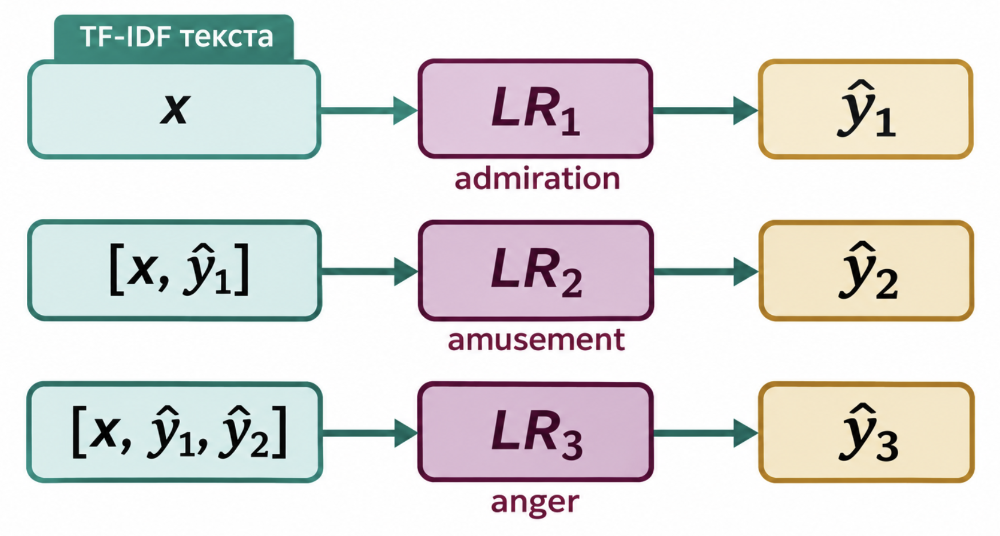

### Сравним на одинаковых признаках

Обучим теперь новый TF-IDF на английских комментариях.

Во время обучения последующим звеньям тоже нужны предыдущие ответы. Получим их на трёх внутренних отложенных частях train: модель делает прогноз для строк, на которых сама не обучалась.

Внутренние части нужны для построения признаков цепочки.

<details>
<summary>Подробнее: взвешивание классов и обучение цепочки</summary>

Логарифмическое взвешивание частоты $1+\ln(tf)$ для $tf>0$ уменьшает влияние многократного повтора одного токена. Нулевая частота остаётся нулевой.

Редкому исходу каждой бинарной задачи можно назначить больший вес:

$$w_c=\frac{n}{2n_c},$$

где $n_c$ - число строк этого исхода в текущем обучении. Это может увеличить и recall, и число ложных срабатываний.

Предыдущие ответы для обучения цепочки можно получать через внутренние прогнозы, как в нашем опыте. Другой вариант - использовать настоящие предыдущие метки трейна. Но на новых данных доступны только предсказания, поэтому во втором случае условия обучения и применения различаются.
</details>

In [ ]:
# ngram_range задаёт униграммы и биграммы, min_df - минимум документов, max_features - предел словаря
# sublinear_tf заменяет положительную частоту на 1 + ln(tf)
emotion_tfidf = TfidfVectorizer(
    ngram_range=(1, 2), min_df=3, max_features=30000, sublinear_tf=True,
)
X_emotion_train = emotion_tfidf.fit_transform(emotion_train["text"])
X_emotion_valid = emotion_tfidf.transform(emotion_valid["text"])

# параметр C задаёт обратную силу регуляризации, balanced повышает вес редкого исхода
# liblinear - алгоритм оптимизации, max_iter - предел итераций, random_state фиксирует случайность
emotion_lr = LogisticRegression(
    C=1, class_weight="balanced", solver="liblinear",
    max_iter=1000, random_state=SEED,
)
emotion_models = {
    # для каждого столбца Y обучается отдельная бинарная модель
    "Независимые LR": OneVsRestClassifier(emotion_lr),

    # base_estimator задаёт модель звена, order=None сохраняет порядок столбцов Y
    # cv=3 строит признаки из внутренних прогнозов; cv=None подставил бы истинные train-метки
    # chain_method="predict" передаёт следующим звеньям ответы 0/1
    "ClassifierChain(LR)": ClassifierChain(
        base_estimator=emotion_lr, order=None, cv=3,
        chain_method="predict", random_state=SEED,
    ),
}
emotion_predictions = {}
for model_name, emotion_model in emotion_models.items():
    emotion_model.fit(X_emotion_train, Y_emotion_train)
    emotion_predictions[model_name] = emotion_model.predict(X_emotion_valid)

print("Признаков текста:", X_emotion_train.shape[1])
print("Порядок цепочки:", ", ".join(emotion_names))

Признаков текста: 30000
Порядок цепочки: admiration, amusement, anger, annoyance, approval, caring, confusion, curiosity, desire, disappointment, disapproval, disgust, embarrassment, excitement, fear, gratitude, grief, joy, love, nervousness, optimism, pride, realization, relief, remorse, sadness, surprise, neutral


### Как оценивать несколько ответов сразу?

Сначала для каждой метки можно посчитать привычные TP, FP и FN. Дальше есть несколько способов собрать общий результат:

| Метрика | Как считаем |
|---|---|
| micro-F1 | Суммируем TP, FP и FN по всем меткам, затем вычисляем F1. Частые метки дают больше вклада |
| macro-F1 | Считаем F1 каждой из 28 меток и берём среднее. Все метки имеют одинаковый вес |
| Полное совпадение | Доля комментариев, для которых угадан весь набор меток. Даже одна лишняя или пропущенная метка делает ответ неверным |

В многометочной задаче micro-F1 в общем случае не равен accuracy.

<details>
<summary>Подробнее: формулы micro-F1, macro-F1 и полного совпадения</summary>

Для каждой метки $j$ считаем $TP_j$, $FP_j$ и $FN_j$:

$$F1_j=\frac{2TP_j}{2TP_j+FP_j+FN_j},\qquad
F1_{macro}=\frac1L\sum_{j=1}^{L}F1_j.$$

Для micro сначала складываем количества ошибок и верных обнаружений:

$$F1_{micro}=\frac{2\sum_jTP_j}{2\sum_jTP_j+\sum_jFP_j+\sum_jFN_j}.$$

Полное совпадение требует правильного ответа во всех столбцах строки:

$$\mathrm{ExactMatch}=\frac1n\sum_{i=1}^{n}\mathbf1\{Y_{i,:}=\hat Y_{i,:}\}.$$

Большое число верных нулей само по себе не увеличивает F1: true negative в формулу не входит.

</details>

In [ ]:
# zero_division=0 задаёт нулевой F1, когда знаменатель его формулы равен нулю
def emotion_scores(prediction):
    return {
        "micro-F1": f1_score(Y_emotion_valid, prediction, average="micro", zero_division=0),
        "macro-F1": f1_score(Y_emotion_valid, prediction, average="macro", zero_division=0),

        # для матриц 0/1 accuracy_score сравнивает целые наборы меток
        "Полное совпадение": accuracy_score(Y_emotion_valid, prediction),
    }

emotion_results = pd.DataFrame({
    name: emotion_scores(prediction)
    for name, prediction in emotion_predictions.items()
}).T
emotion_results.round(3)

,micro-F1,macro-F1,Полное совпадение
Независимые LR,0.499,0.450,0.242
ClassifierChain(LR),0.491,0.436,0.233


В этом запуске независимые модели оказались немного лучше по обеим F1 и полному совпадению. Значит, сама по себе встречаемость эмоций в парах ещё не даёт основания заменить простой вариант цепочкой.

Посмотрим отдельно на метки: рядом с F1 оставим число комментариев с этой меткой в вализации. На графике оно обозначено как `n`. Изменению качества редкой эмоции может соответствовать всего несколько комментариев.

In [ ]:
emotion_label_results = pd.DataFrame({
    "Примеров в train": Y_emotion_train.sum(axis=0),
    "Примеров в validation": Y_emotion_valid.sum(axis=0),
}, index=emotion_names)
for model_name, prediction in emotion_predictions.items():
    # average=None возвращает отдельный F1 каждой метки
    emotion_label_results[model_name] = f1_score(
        Y_emotion_valid, prediction, average=None, zero_division=0,
    )
emotion_label_results.loc[["admiration", "gratitude", "joy", "pride", "relief", "neutral"]].round(3)

,Примеров в train,Примеров в validation,Независимые LR,ClassifierChain(LR)
admiration,4106,485,0.661,0.661
gratitude,2599,344,0.884,0.891
joy,1436,170,0.503,0.467
pride,110,15,0.500,0.552
relief,153,18,0.167,0.100
neutral,14145,1759,0.635,0.635


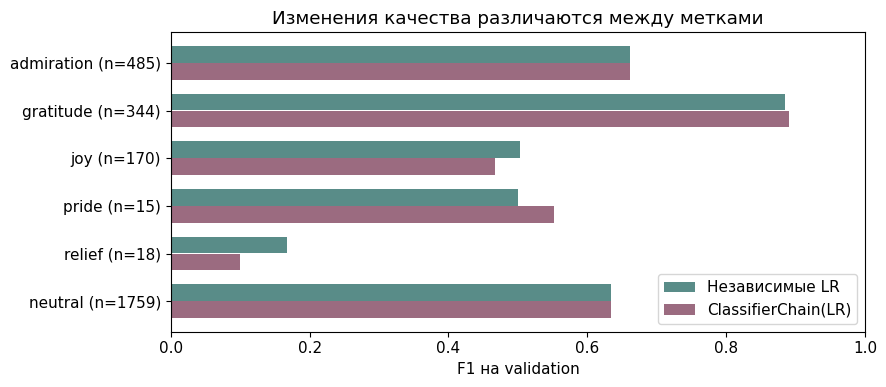

In [ ]:
emotion_plot_labels = ["admiration", "gratitude", "joy", "pride", "relief", "neutral"]
emotion_plot_table = emotion_label_results.loc[emotion_plot_labels]
emotion_plot_positions = np.arange(len(emotion_plot_table))
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(emotion_plot_positions - 0.18, emotion_plot_table["Независимые LR"],
        height=0.35, label="Независимые LR", color=COLORS[2])
ax.barh(emotion_plot_positions + 0.18, emotion_plot_table["ClassifierChain(LR)"],
        height=0.35, label="ClassifierChain(LR)", color=COLORS[0])
ax.set_yticks(emotion_plot_positions, [
    f"{label} (n={int(emotion_plot_table.loc[label, 'Примеров в validation'])})"
    for label in emotion_plot_labels
])
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("F1 на validation")
ax.set_title("Изменения качества различаются между метками")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

На графике видно, что среднее скрывает разные изменения: для `gratitude` цепочка немного лучше, для `joy` хуже. У `pride` и `relief` мало размеченных примеров, поэтому небольшой сдвиг числа ответов заметно меняет F1.


In [ ]:
def emotion_label_names(row):
    return ", ".join(np.array(emotion_names)[np.asarray(row).astype(bool)]) or "нет меток"

emotion_case_ids = ["ee55qb6", "efb6lk2"]
emotion_case_positions = pd.Index(emotion_valid["id"]).get_indexer(emotion_case_ids)
emotion_cases = emotion_valid.iloc[emotion_case_positions][["id", "text"]].copy()
emotion_cases["Разметка"] = [
    emotion_label_names(row) for row in Y_emotion_valid[emotion_case_positions]
]
for model_name, prediction in emotion_predictions.items():
    emotion_cases[model_name] = [
        emotion_label_names(row) for row in prediction[emotion_case_positions]
    ]
with pd.option_context("display.max_colwidth", None):
    display(emotion_cases.set_index("id"))

,text,Разметка,Независимые LR,ClassifierChain(LR)
id,,,,
ee55qb6,haha! She is so creepy at times. What a great actress.,"admiration, amusement","admiration, amusement, disgust","admiration, amusement"
efb6lk2,"I am confused. I don't understand how that relates to what I said. Could you explain? Sorry, maybe I'm just tired lol","amusement, confusion, curiosity, remorse","amusement, confusion, curiosity, remorse","amusement, confusion, curiosity"


В комментарии про актрису независимые модели добавили `disgust`, а цепочка оставила только `admiration` и `amusement`, как в разметке. Во втором комментарии независимые модели угадали все четыре эмоции, а цепочка пропустила `remorse`, хотя в тексте есть *Sorry*.

Эти изменения показывают, что модели приняли разные решения. Чтобы установить, какое именно предыдущее предсказание повлияло на ответ, одного такого сравнения недостаточно.

**Вопрос:** согласны ли вы со всеми метками второго комментария? Как нехватка контекста обсуждения может влиять на разметку и на оценку модели?

**Задание 4. Поменяем порядок**

Как думаете, сохранится ли качество, если начать цепочку с последней метки? Проверьте обратный порядок, оставив TF-IDF, настройки LR и validation прежними.

Сравните micro-F1 и macro-F1 с независимыми моделями и первой цепочкой. Почему порядок вообще может влиять на результат?

In [ ]:
emotion_reverse = ClassifierChain(
    base_estimator=emotion_lr,
    # начинаем с последнего столбца Y, а остальные настройки сохраняем
    order=list(reversed(range(len(emotion_names)))),
    cv=3, chain_method="predict", random_state=SEED,
)
emotion_reverse.fit(X_emotion_train, Y_emotion_train)
# predict вернёт столбцы в исходном порядке Y; переставлять их для метрик не нужно
emotion_reverse_prediction = emotion_reverse.predict(X_emotion_valid)

emotion_order_results = emotion_results.copy()
emotion_order_results.loc["Цепочка в обратном порядке"] = emotion_scores(emotion_reverse_prediction)
emotion_order_results.round(3)

,micro-F1,macro-F1,Полное совпадение
Независимые LR,0.499,0.450,0.242
ClassifierChain(LR),0.491,0.436,0.233
Цепочка в обратном порядке,0.492,0.441,0.231


Обратный порядок немного изменил результат, но независимые LR по-прежнему впереди. В цепочке меняются доступные признаки: первая модель видит только текст, последняя - ещё и все предыдущие предсказания. Поэтому порядок имеет значение, а самый удачный порядок для одного корпуса не обязан работать на другом.

Для этого опыта разумно оставить независимые LR. ClassifierChain полезно держать среди вариантов для задачи с несколькими метками, но сравнивать с простым решением на одинаковых признаках.

## Что получилось и когда это пригодится?

| Вопрос | Что получили |
|---|---|
| Какие сочетания характерны для корпуса? | PMI/PPMI отделяет частое соседство от более сильного, чем ожидается при независимости |
| Можно ли заменить тысячи признаков меньшим числом координат? | LSA строит новые векторы документов |
| Помогут ли связи между несколькими метками? | ClassifierChain добавляет предыдущие предсказания к признакам текста |

Получились разные инструменты для разных решений: исследовать язык корпуса, изменить представление документов или способ предсказывать несколько ответов. Во всех трёх случаях численный результат полезно проверять на конкретных текстах.

> Основная часть закончена. В приложении вернёмся к RuReviews и рассмотрим отдельное ограничение: что делать, если хранить большой словарь неудобно.

## Приложение. Feature hashing

Этот раздел можно пропустить. Здесь снова работаем с **русскими отзывами RuReviews** и одной меткой тональности.

Представим, что отзывы приходят каждый день, а словарь с названиями, опечатками и сочетаниями слов становится всё больше. Его приходится хранить и передавать вместе с моделью. Можно ли заранее задать число координат и обрабатывать разные порции текста по одному правилу?

**Feature hashing, или хеширование признаков, вычисляет номер столбца для токена с помощью хеш-функции.** Соответствие «токен - номер столбца» не нужно хранить в словаре. Размер пространства задаётся заранее.

Проверим это на реальном отзыве, а затем посмотрим на качество и память. Hashing отвечает за назначение столбцов, TF-IDF - за их веса, а их можно сочетать. На обычном небольшом корпусе словарь остаётся удобным решением, особенно когда нужно объяснять прогноз через конкретные слова.

### Что такое хеш-функция?

**Хеш-функция вычисляет число по входной строке.** При одинаковых настройках один и тот же токен всегда даёт одно и то же число, в каком бы отзыве он ни встретился. Этому правилу не нужно обучаться на корпусе.

Полученное число не описывает смысл слова: похожие слова могут иметь совсем разные хеши. Возьмём настоящий отзыв «Супер джинсы!» и вычислим хеш каждого токена.

In [ ]:
# используем MurmurHash3, как HashingVectorizer
# Python hash() может меняться между запусками
from sklearn.utils import murmurhash3_32

hash_example = train.set_index("id").loc[64676]
print(hash_example["text_raw"])
example_words = CountVectorizer().build_analyzer()(hash_example["text"])

# seed=0 фиксирует настройку хеш-функции для всех токенов
word_hashes = pd.DataFrame({
    "Токен": example_words,
    "Хеш": [murmurhash3_32(word, seed=0) for word in example_words],
})
word_hashes

Супер джинсы!


,Токен,Хеш
0,супер,807985047
1,джинсы,-1785622423


### От хеша к вектору документа

Числа получились большими, а вектор мы хотим ограничить 1024 столбцами. Переведём каждый хеш в индекс от 0 до 1023. Дальше начинаем с нулевого вектора: каждое вхождение токена добавляет единицу в свой столбец.

Сначала возьмём самый простой вариант: 1024 столбца, положительные вклады и отсутствие нормировки. Покажем индексы токенов и полученные ненулевые координаты.

<details>
<summary>Подробнее: формула индекса и накопление частот</summary>

Для токенов нашего примера номер столбца равен:

$$j(w)=|h(w)|\bmod m,$$

где $h(w)$ - хеш, $m$ - число столбцов.

Без знаков значение координаты $j$ - сумма частот всех токенов документа, получивших этот индекс:

$$x_j=\sum_{w:j(w)=j}\operatorname{tf}(w).$$

Два разных токена могут дать один индекс. Векторы в `HashingVectorizer` хранятся разреженно, хотя возможное число столбцов фиксировано.

</details>

In [ ]:
n_features = 2**10
# берём модуль хеша и остаток от деления на число столбцов
hash_steps = word_hashes.assign(
    **{"Столбец": word_hashes["Хеш"].abs() % n_features}
)
display(hash_steps)

# n_features задаёт число столбцов, alternate_sign=False даёт вклад +1, norm=None отключает нормировку
small_hasher = HashingVectorizer(
    n_features=n_features, alternate_sign=False, norm=None
)
example_vector = small_hasher.transform([hash_example["text"]])
print("Размер матрицы:", example_vector.shape)
pd.DataFrame({
    "Столбец": example_vector.indices,
    "Значение": example_vector.data,
})

,Токен,Хеш,Столбец
0,супер,807985047,919
1,джинсы,-1785622423,919


Размер матрицы: (1, 1024)


,Столбец,Значение
0,919,2.0


Два разных слова попали в столбец 919. Это **коллизия**: хеши у слов разные, но остаток от деления совпал. Коллизия может возникнуть и при совпадении самих хешей.

Теперь значение `2` хранит суммарное число вхождений, попавших в этот столбец. По одному вектору уже нельзя восстановить, какие слова его сформировали.

У `CountVectorizer` этим двум токенам соответствовали бы отдельные столбцы. Его словарь строится при `fit` и при последующих вызовах `transform` не растёт: неизвестные токены игнорируются.

**Вопрос:** сможет ли модель различить два однословных сообщения, если их токены попали в один столбец и имеют одинаковый вклад?

### Откуда берутся отрицательные значения?

По умолчанию хеш определяет не только столбец, но и вклад `+1` или `-1`. Для одного токена знак постоянен. Отрицательное значение не означает отрицательную тональность.

Знаки помогают уменьшить систематическое завышение сходства из-за коллизий. Но для отдельного отзыва вклады могут сократиться полностью. Проверим это на тех же двух словах.

<details>
<summary>Подробнее: signed hashing и скалярные произведения</summary>

Если $s(w)\in\{-1,+1\}$ - знак токена, то:

$$x_j=\sum_{w:j(w)=j}s(w)\operatorname{tf}(w).$$

При вычислении скалярного произведения коллизия добавляет слагаемые от разных слов. Без знаков такие случайные совпадения неотрицательны. При достаточно равномерном распределении хешей знаки позволяют этим вкладам компенсироваться в среднем.

</details>

In [ ]:
# alternate_sign=True включает знаки вкладов
signed_hasher = HashingVectorizer(
    n_features=2**10, alternate_sign=True, norm=None
)
token_vectors = signed_hasher.transform(example_words)
pd.DataFrame({
    "Токен": example_words,
    "Столбец": token_vectors.indices,
    "Вклад": token_vectors.data.astype(int),
})

,Токен,Столбец,Вклад
0,супер,919,1
1,джинсы,919,-1


In [ ]:
collision_rows = []
for dimensions, signed in [(2**10, False), (2**10, True), (2**16, True)]:
    hasher = HashingVectorizer(n_features=dimensions, norm=None, alternate_sign=signed)
    vector = hasher.transform([hash_example["text"]])

    # удаляем явные нули после сокращения вкладов, чтобы nnz отражал итоговый результат
    vector.eliminate_zeros()
    collision_rows.append({
        "Столбцов": dimensions,
        "alternate_sign": signed,
        "Ненулевых координат": vector.nnz,
        "Индексы": vector.indices.tolist(),
        "Значения": vector.data.tolist(),
    })
pd.DataFrame(collision_rows)

,Столбцов,alternate_sign,Ненулевых координат,Индексы,Значения
0,1024,False,1,[919],[2.0]
1,1024,True,0,[],[]
2,65536,True,2,"[28567, 57239]","[-1.0, 1.0]"


При 1024 столбцах без знаков получаем `1 + 1 = 2`. Со знаками получаем `1 - 1 = 0`: непустой отзыв превращается в нулевой вектор.

При 65 536 столбцах эти два слова разделились. Увеличение размерности обычно уменьшает число коллизий, но не гарантирует их полного отсутствия.

L2-нормировка - другая операция: она приводит уже полученный ненулевой вектор к единичной длине.

### Можно ли обрабатывать отзывы по частям?

Допустим, отзывы приходят порциями. Нам нужно, чтобы одинаковые токены кодировались одинаково во всех порциях. У hashing это правило определяется алгоритмом и настройками.

Для проверки возьмём шесть настоящих отзывов: преобразуем их целиком, а затем двумя порциями по три. Матрицы должны совпасть.

In [ ]:
from scipy.sparse import vstack

batch_hasher = HashingVectorizer(n_features=2**16, alternate_sign=True, norm="l2")
batch_texts = train["text"].iloc[:6]
whole_batch = batch_hasher.transform(batch_texts)

# vstack соединяет строки порций и сохраняет разреженное хранение
separate_batches = vstack([
    batch_hasher.transform(batch_texts.iloc[:3]),
    batch_hasher.transform(batch_texts.iloc[3:]),
], format="csr")

print("Размер матрицы:", separate_batches.shape)
print("Число различающихся элементов:", (whole_batch != separate_batches).nnz)

Размер матрицы: (6, 65536)
Число различающихся элементов: 0


Результаты совпали. На большом корпусе можно преобразовывать порции независимо и передавать их дальше, не собирая всю матрицу в памяти. Если хотим и обучать классификатор по порциям, нужен алгоритм с поддержкой такого обучения. Наша логистическая регрессия ниже обучается обычным способом на всей тренировочной матрице.

Вариант со словарём тоже умеет преобразовывать тексты по частям, если все порции используют один и тот же уже обученный векторизатор. Преимущество hashing здесь - отсутствие предварительного построения и хранения этого словаря.

### Какой вариант выбрать для классификации?

Сравним обычные частоты с hashing при двух размерах пространства. В обоих случаях используем униграммы, L2-нормировку и одинаковую логистическую регрессию.

`CountVectorizer` сохраняет все слова выбранной токенизации, без `min_df` и ограничения словаря.

In [ ]:
count_vec = CountVectorizer()
count_train = normalize(count_vec.fit_transform(train["text"]))
count_valid = normalize(count_vec.transform(valid["text"]))
count_clf = LogisticRegression(C=1.0, max_iter=500, random_state=SEED)
count_clf.fit(count_train, train["label"])
count_pred = count_clf.predict(count_valid)

hash_results = [{
    "Представление": "Частоты + L2",
    "Столбцов": count_train.shape[1],
    "Нулевых строк train": int((count_train.getnnz(axis=1) == 0).sum()),
    "Macro-F1 на validation": f1_score(valid["label"], count_pred, average="macro"),
}]
hash_models = {}
for dimensions in [2**10, 2**16]:
    hasher = HashingVectorizer(n_features=dimensions, alternate_sign=True, norm="l2")
    hash_train = hasher.transform(train["text"])
    hash_valid = hasher.transform(valid["text"])
    hash_train.eliminate_zeros()
    hash_valid.eliminate_zeros()
    clf = LogisticRegression(C=1.0, max_iter=500, random_state=SEED)
    clf.fit(hash_train, train["label"])
    prediction = clf.predict(hash_valid)
    hash_models[dimensions] = (hasher, clf)
    hash_results.append({
        "Представление": f"Hashing {dimensions} + L2",
        "Столбцов": dimensions,
        "Нулевых строк train": int((hash_train.getnnz(axis=1) == 0).sum()),
        "Macro-F1 на validation": f1_score(valid["label"], prediction, average="macro"),
    })
hash_results = pd.DataFrame(hash_results).set_index("Представление")
hash_results.round(3)

,Столбцов,Нулевых строк train,Macro-F1 на validation
Представление,,,
Частоты + L2,25255,17,0.730
Hashing 1024 + L2,1024,18,0.687
Hashing 65536 + L2,65536,17,0.733


Теперь посмотрим на массив весов классификатора. Для каждого класса модель хранит вес каждой координаты.

Ниже учитываем только `coef_`. Словарь, матрицы документов, свободные члены и временные массивы сюда не входят, поэтому это не замер всей памяти процесса.

<details>
<summary>Подробнее: число весов, байты и MiB</summary>

В этом трёхклассовом опыте матрица весов имеет размер $(3,m)$, где $m$ - число признаков. При хранении каждого числа в 64 битах один элемент занимает 8 байт.

Например, для 65 536 столбцов получаем $3\cdot65536\cdot8=1\,572\,864$ байта, или 1.5 MiB. Один MiB равен $2^{20}$ байтам, в таблице памяти LSA использовались MB, то есть миллионы байт. Здесь сравниваем варианты внутри одной таблицы.

</details>

In [ ]:
models_for_size = {"Частоты + L2": count_clf}
models_for_size.update({
    f"Hashing {dimensions} + L2": model
    for dimensions, (_, model) in hash_models.items()
})

# shape - размеры массива весов, size - число элементов, nbytes - их объём в байтах
# деление на 2**20 переводит байты в MiB
pd.DataFrame([
    {
        "Представление": name,
        "Форма coef_": model.coef_.shape,
        "Число весов": model.coef_.size,
        "Память coef_, MiB": model.coef_.nbytes / 2**20,
    }
    for name, model in models_for_size.items()
]).set_index("Представление").round(3)

,Форма coef_,Число весов,"Память coef_, MiB"
Представление,,,
Частоты + L2,"(3, 25255)",75765,0.578
Hashing 1024 + L2,"(3, 1024)",3072,0.023
Hashing 65536 + L2,"(3, 65536)",196608,1.500


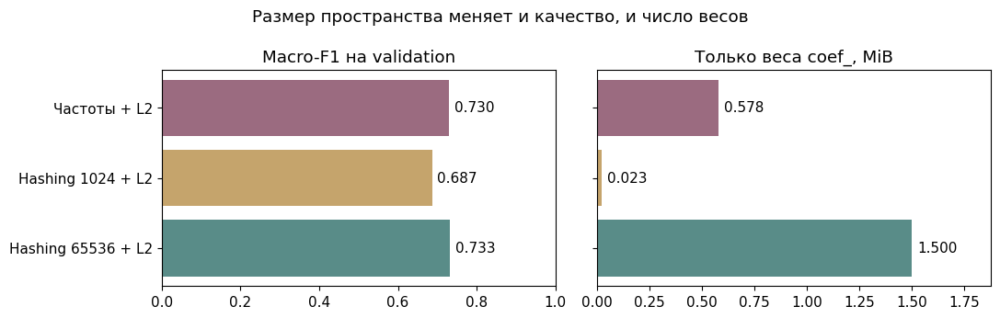

In [ ]:
hash_names = list(models_for_size)
hash_plot_memory = [models_for_size[name].coef_.nbytes / 2**20 for name in hash_names]
hash_plot_f1 = hash_results.loc[hash_names, "Macro-F1 на validation"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for axis, values, title in [
    (axes[0], hash_plot_f1, "Macro-F1 на validation"),
    (axes[1], hash_plot_memory, "Только веса coef_, MiB"),
]:
    bars = axis.barh(hash_names, values, color=COLORS)
    axis.invert_yaxis()
    axis.set_title(title)
    axis.bar_label(bars, fmt="%.3f", padding=4)
axes[0].set_xlim(0, 1)
axes[1].set_xlim(0, max(hash_plot_memory) * 1.25)
axes[1].tick_params(labelleft=False)
fig.suptitle("Размер пространства меняет и качество, и число весов")
plt.tight_layout()
plt.show()

В маленьком пространстве качество заметно снизилось. При 65 536 столбцах hashing оказался близок к варианту со словарём, но массив весов у него больше.

Для нас тут несколько разных требований:

| Что нужно в задаче | Что учитывать при выборе |
|---|---|
| Отчёт о характерных словах и объяснение их вклада | У векторизатора со словарём каждому столбцу соответствует известный токен |
| Обработка больших порций текстов без построения общего словаря | Hashing даёт фиксированное пространство и одинаковое правило кодирования |
| Классификатор с ограничениями по памяти | Проверяем качество и расходы памяти при разных `n_features`, коллизии могут ухудшить результат |


**Задание. Выберем размер пространства**

Добавьте к сравнению `2**12` столбцов. Где этот вариант оказался по Macro-F1 и размеру массива весов?

Затем предложите представление для двух случаев: нужно автоматически классифицировать большой поток отзывов, нужно подготовить отчёт с характерными словами каждого класса. Какие ограничения по памяти и требования к объяснению результатов вы бы уточнили перед выбором? Обоснуйте своё решение. Почему одного числа нулевых строк недостаточно, чтобы оценить последствия коллизий?